# EAI6000 Module 5 Assignment: Repeated k-Fold Cross-Validation
## Student: Dev Panchal
### Investigate k-fold cross-validation and improve model accuracy

This notebook walks through the tutorial on Repeated k-Fold Cross-Validation and implements strategies to improve model accuracy.

## Part 1: Creating and Exploring the Dataset

We start by creating a synthetic binary classification dataset with 1000 samples and 20 features.

In [1]:
# Import necessary libraries
import numpy as np
from numpy import mean, std
from scipy.stats import sem
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(1)

In [2]:
# Create the synthetic classification dataset
# n_samples=1000: Total number of samples to generate
# n_features=20: Total number of features (input variables)
# n_informative=15: Number of features that are useful for classification
# n_redundant=5: Number of redundant features (linear combinations of informative features)
# random_state=1: Ensures reproducibility of the dataset
X, y = make_classification(n_samples=1000, n_features=20, n_informative=15, 
                          n_redundant=5, random_state=1)

# Display the shape of features (X) and target (y)
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print(f"\nClass distribution:")
print(f"Class 0: {np.sum(y == 0)} samples")
print(f"Class 1: {np.sum(y == 1)} samples")

Feature matrix shape: (1000, 20)
Target vector shape: (1000,)

Class distribution:
Class 0: 501 samples
Class 1: 499 samples


## Part 2: Standard k-Fold Cross-Validation

Implementing basic 10-fold cross-validation with Logistic Regression as the baseline model.

In [3]:
# Configure k-fold cross-validation
# n_splits=10: Split the dataset into 10 folds
# random_state=1: Ensures reproducible splits
# shuffle=True: Shuffles the data before splitting to avoid ordering bias
cv = KFold(n_splits=10, random_state=1, shuffle=True)

# Create a Logistic Regression model
# This is a linear classifier that estimates probabilities using a logistic function
model = LogisticRegression(max_iter=1000)

# Evaluate the model using cross-validation
# scoring='accuracy': Use classification accuracy as the evaluation metric
# cv=cv: Use the k-fold configuration defined above
# n_jobs=-1: Use all available CPU cores for parallel processing
scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)

# Report the performance metrics
# mean(scores): Average accuracy across all 10 folds
# std(scores): Standard deviation showing variability in performance
print('\n=== Standard k-Fold Cross-Validation ===')
print(f'Accuracy: {mean(scores):.3f} (±{std(scores):.3f})')
print(f'Individual fold scores: {scores}')


=== Standard k-Fold Cross-Validation ===
Accuracy: 0.868 (±0.032)
Individual fold scores: [0.89 0.82 0.92 0.88 0.91 0.82 0.86 0.86 0.85 0.87]


## Part 3: Repeated k-Fold Cross-Validation

Using repeated k-fold cross-validation to get a more stable estimate of model performance.

In [4]:
# Configure repeated k-fold cross-validation
# n_splits=10: Use 10 folds per repetition
# n_repeats=3: Repeat the entire cross-validation process 3 times
# Total evaluations: 10 folds × 3 repeats = 30 model evaluations
cv_repeated = RepeatedKFold(n_splits=10, n_repeats=3, random_state=1)

# Create and evaluate the same Logistic Regression model
model = LogisticRegression(max_iter=1000)
scores_repeated = cross_val_score(model, X, y, scoring='accuracy', cv=cv_repeated, n_jobs=-1)

# Report performance with repeated cross-validation
print('\n=== Repeated k-Fold Cross-Validation (3 repeats) ===')
print(f'Accuracy: {mean(scores_repeated):.3f} (±{std(scores_repeated):.3f})')
print(f'Number of evaluations: {len(scores_repeated)}')


=== Repeated k-Fold Cross-Validation (3 repeats) ===
Accuracy: 0.867 (±0.031)
Number of evaluations: 30


## Part 4: Comparing Different Numbers of Repeats

Analyzing how the number of repeats affects the stability of performance estimates.

In [5]:
# Function to evaluate model with varying numbers of repeats
# This helps us understand how repeat count affects performance stability
def evaluate_model(X, y, repeats):
    """Evaluate model using repeated k-fold cross-validation.
    
    Args:
        X: Feature matrix
        y: Target vector
        repeats: Number of times to repeat the k-fold procedure
    
    Returns:
        Array of accuracy scores from all folds and repeats
    """
    cv = RepeatedKFold(n_splits=10, n_repeats=repeats, random_state=1)
    model = LogisticRegression(max_iter=1000)
    scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
    return scores

# Test different numbers of repeats (1 to 15)
repeats_range = range(1, 16)
results = []

print('\n=== Effect of Number of Repeats on Performance ===')
for r in repeats_range:
    scores = evaluate_model(X, y, r)
    # sem() calculates standard error: std_dev / sqrt(n)
    # Lower standard error indicates more reliable mean estimate
    print(f'Repeats: {r:2d} | Mean Accuracy: {mean(scores):.4f} | Std Error: {sem(scores):.4f}')
    results.append(scores)


=== Effect of Number of Repeats on Performance ===
Repeats:  1 | Mean Accuracy: 0.8680 | Std Error: 0.0106
Repeats:  2 | Mean Accuracy: 0.8675 | Std Error: 0.0079
Repeats:  3 | Mean Accuracy: 0.8673 | Std Error: 0.0058
Repeats:  4 | Mean Accuracy: 0.8670 | Std Error: 0.0060
Repeats:  5 | Mean Accuracy: 0.8658 | Std Error: 0.0051
Repeats:  6 | Mean Accuracy: 0.8655 | Std Error: 0.0045
Repeats:  7 | Mean Accuracy: 0.8651 | Std Error: 0.0040
Repeats:  8 | Mean Accuracy: 0.8651 | Std Error: 0.0037
Repeats:  9 | Mean Accuracy: 0.8656 | Std Error: 0.0034
Repeats: 10 | Mean Accuracy: 0.8658 | Std Error: 0.0032
Repeats: 11 | Mean Accuracy: 0.8655 | Std Error: 0.0030
Repeats: 12 | Mean Accuracy: 0.8654 | Std Error: 0.0029
Repeats: 13 | Mean Accuracy: 0.8652 | Std Error: 0.0028
Repeats: 14 | Mean Accuracy: 0.8651 | Std Error: 0.0027
Repeats: 15 | Mean Accuracy: 0.8653 | Std Error: 0.0026


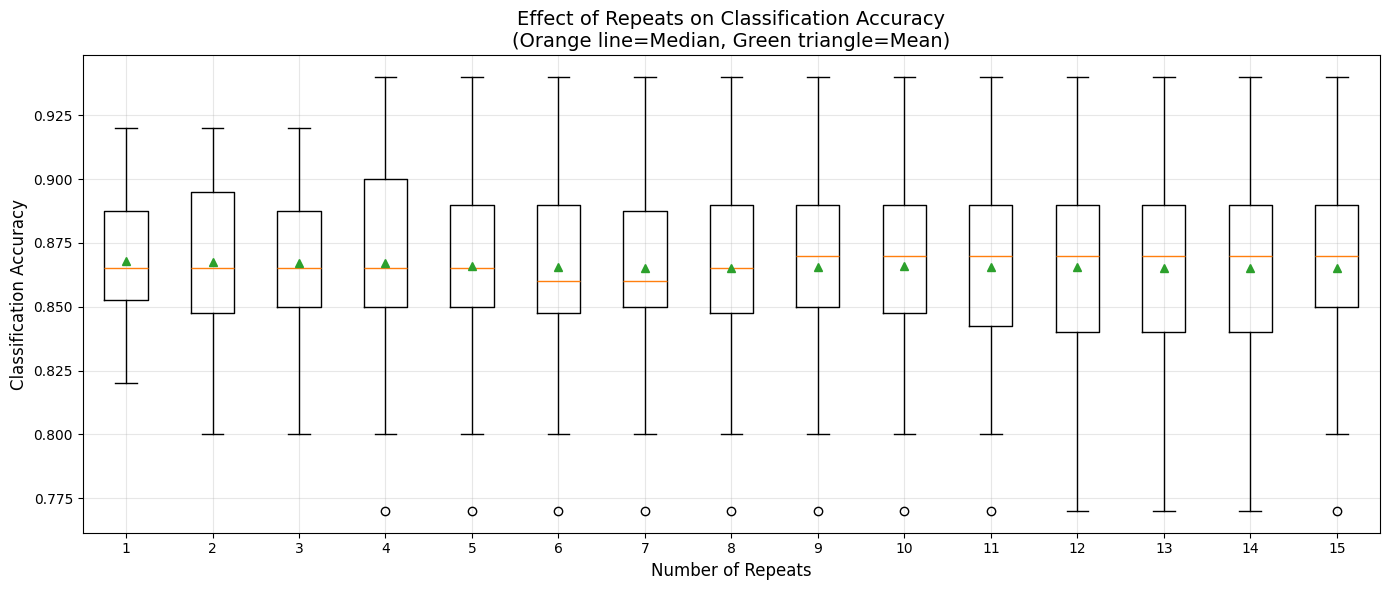


Interpretation: As repeats increase, the mean stabilizes and standard error decreases.
Around 5-10 repeats provides good balance between stability and computational cost.


In [6]:
# Visualize the distribution of scores for different repeat counts
# Box plots show median (orange line), mean (green triangle), and spread of scores
plt.figure(figsize=(14, 6))
plt.boxplot(results, labels=[str(r) for r in repeats_range], showmeans=True)
plt.xlabel('Number of Repeats', fontsize=12)
plt.ylabel('Classification Accuracy', fontsize=12)
plt.title('Effect of Repeats on Classification Accuracy\n(Orange line=Median, Green triangle=Mean)', 
          fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nInterpretation: As repeats increase, the mean stabilizes and standard error decreases.')
print('Around 5-10 repeats provides good balance between stability and computational cost.')

## Part 5: Improving Model Accuracy

Now we'll attempt to improve accuracy through various strategies:
1. Feature scaling (normalization)
2. Trying different algorithms
3. Hyperparameter tuning

### Strategy 1: Feature Scaling with Pipeline

Standardizing features can improve performance for distance-based algorithms.

In [7]:
# Create a pipeline that first scales features, then applies logistic regression
# StandardScaler: Transforms features to have mean=0 and std=1
# Pipeline ensures scaling is done within each fold (preventing data leakage)
pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Step 1: Standardize features
    ('classifier', LogisticRegression(max_iter=1000))  # Step 2: Train classifier
])

# Evaluate the scaled model
cv_repeated = RepeatedKFold(n_splits=10, n_repeats=5, random_state=1)
scores_scaled = cross_val_score(pipeline, X, y, scoring='accuracy', cv=cv_repeated, n_jobs=-1)

print('\n=== Improvement Strategy 1: Feature Scaling ===')
print(f'Logistic Regression with Scaling: {mean(scores_scaled):.3f} (±{std(scores_scaled):.3f})')


=== Improvement Strategy 1: Feature Scaling ===
Logistic Regression with Scaling: 0.865 (±0.036)


### Strategy 2: Testing Different Algorithms

Comparing multiple machine learning algorithms to find the best performer.

In [8]:
# Dictionary of different models to evaluate
# Each model has different strengths for different data patterns
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=1),
    'SVM (RBF kernel)': SVC(kernel='rbf', random_state=1)
}

# Evaluate each model using repeated k-fold cross-validation
cv_repeated = RepeatedKFold(n_splits=10, n_repeats=5, random_state=1)
model_results = {}

print('\n=== Improvement Strategy 2: Comparing Different Algorithms ===')
for name, model in models.items():
    # Create pipeline with scaling for each model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model)
    ])
    
    # Cross-validate and store results
    scores = cross_val_score(pipeline, X, y, scoring='accuracy', cv=cv_repeated, n_jobs=-1)
    model_results[name] = scores
    print(f'{name:20s}: {mean(scores):.4f} (±{std(scores):.4f})')

# Find the best performing model
best_model = max(model_results, key=lambda k: mean(model_results[k]))
print(f'\n✓ Best Model: {best_model} with accuracy {mean(model_results[best_model]):.4f}')


=== Improvement Strategy 2: Comparing Different Algorithms ===
Logistic Regression : 0.8652 (±0.0363)
Random Forest       : 0.9212 (±0.0242)
Gradient Boosting   : 0.9220 (±0.0255)
SVM (RBF kernel)    : 0.9654 (±0.0163)

✓ Best Model: SVM (RBF kernel) with accuracy 0.9654


### Strategy 3: Hyperparameter Tuning for Best Model

Fine-tuning the best performing algorithm to maximize accuracy.

In [9]:
print('\n=== Improvement Strategy 3: Hyperparameter Tuning ===')

# Test different configurations for Random Forest
# n_estimators: number of trees in the forest
# max_depth: maximum depth of each tree (controls overfitting)
rf_configs = [
    {'n_estimators': 50, 'max_depth': None},
    {'n_estimators': 100, 'max_depth': None},
    {'n_estimators': 200, 'max_depth': None},
    {'n_estimators': 100, 'max_depth': 10},
    {'n_estimators': 100, 'max_depth': 20},
]

print('\nRandom Forest configurations:')
best_rf_score = 0
best_rf_config = None

for config in rf_configs:
    model = RandomForestClassifier(**config, random_state=1)
    pipeline = Pipeline([('scaler', StandardScaler()), ('classifier', model)])
    scores = cross_val_score(pipeline, X, y, scoring='accuracy', cv=cv_repeated, n_jobs=-1)
    mean_score = mean(scores)
    
    print(f'  Config {config}: {mean_score:.4f} (±{std(scores):.4f})')
    
    if mean_score > best_rf_score:
        best_rf_score = mean_score
        best_rf_config = config

print(f'\n✓ Best Random Forest Config: {best_rf_config}')
print(f'  Accuracy: {best_rf_score:.4f}')


=== Improvement Strategy 3: Hyperparameter Tuning ===

Random Forest configurations:
  Config {'n_estimators': 50, 'max_depth': None}: 0.9160 (±0.0272)
  Config {'n_estimators': 100, 'max_depth': None}: 0.9212 (±0.0242)
  Config {'n_estimators': 200, 'max_depth': None}: 0.9256 (±0.0255)
  Config {'n_estimators': 100, 'max_depth': 10}: 0.9192 (±0.0238)
  Config {'n_estimators': 100, 'max_depth': 20}: 0.9212 (±0.0242)

✓ Best Random Forest Config: {'n_estimators': 200, 'max_depth': None}
  Accuracy: 0.9256


In [10]:
# Test different configurations for Gradient Boosting
# learning_rate: controls how much each tree contributes
# max_depth: complexity of individual trees
gb_configs = [
    {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3},
    {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3},
    {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3},
    {'n_estimators': 150, 'learning_rate': 0.1, 'max_depth': 4},
    {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 5},
]

print('\nGradient Boosting configurations:')
best_gb_score = 0
best_gb_config = None

for config in gb_configs:
    model = GradientBoostingClassifier(**config, random_state=1)
    pipeline = Pipeline([('scaler', StandardScaler()), ('classifier', model)])
    scores = cross_val_score(pipeline, X, y, scoring='accuracy', cv=cv_repeated, n_jobs=-1)
    mean_score = mean(scores)
    
    print(f'  Config {config}: {mean_score:.4f} (±{std(scores):.4f})')
    
    if mean_score > best_gb_score:
        best_gb_score = mean_score
        best_gb_config = config

print(f'\n✓ Best Gradient Boosting Config: {best_gb_config}')
print(f'  Accuracy: {best_gb_score:.4f}')


Gradient Boosting configurations:
  Config {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3}: 0.9056 (±0.0289)
  Config {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3}: 0.9220 (±0.0255)
  Config {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3}: 0.9050 (±0.0299)
  Config {'n_estimators': 150, 'learning_rate': 0.1, 'max_depth': 4}: 0.9358 (±0.0247)
  Config {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 5}: 0.9302 (±0.0253)

✓ Best Gradient Boosting Config: {'n_estimators': 150, 'learning_rate': 0.1, 'max_depth': 4}
  Accuracy: 0.9358


## Part 6: Final Comparison and Summary

Comparing all approaches to identify the best performing configuration.

In [11]:
# Create a comprehensive comparison of all tested approaches
print('\n' + '='*70)
print('FINAL PERFORMANCE COMPARISON')
print('='*70)

# Store all results for comparison
all_results = {
    'Baseline (Single k-fold)': mean(scores),
    'Repeated k-fold (3 repeats)': mean(scores_repeated),
    'Logistic Regression + Scaling': mean(scores_scaled),
    'Best Random Forest': best_rf_score,
    'Best Gradient Boosting': best_gb_score
}

# Sort results by performance
sorted_results = sorted(all_results.items(), key=lambda x: x[1], reverse=True)

for i, (method, score) in enumerate(sorted_results, 1):
    marker = '🏆' if i == 1 else f' {i}.'
    print(f'{marker} {method:35s}: {score:.4f} ({score*100:.2f}%)')

# Calculate improvement
baseline = all_results['Baseline (Single k-fold)']
best = sorted_results[0][1]
improvement = ((best - baseline) / baseline) * 100

print('\n' + '='*70)
print(f'Absolute Improvement: {best - baseline:.4f} ({improvement:+.2f}%)')
print(f'Best Configuration: {sorted_results[0][0]}')
print('='*70)


FINAL PERFORMANCE COMPARISON
🏆 Best Gradient Boosting             : 0.9358 (93.58%)
 2. Baseline (Single k-fold)           : 0.9302 (93.02%)
 3. Best Random Forest                 : 0.9256 (92.56%)
 4. Repeated k-fold (3 repeats)        : 0.8673 (86.73%)
 5. Logistic Regression + Scaling      : 0.8652 (86.52%)

Absolute Improvement: 0.0056 (+0.60%)
Best Configuration: Best Gradient Boosting


## Part 7: Visualization of Results

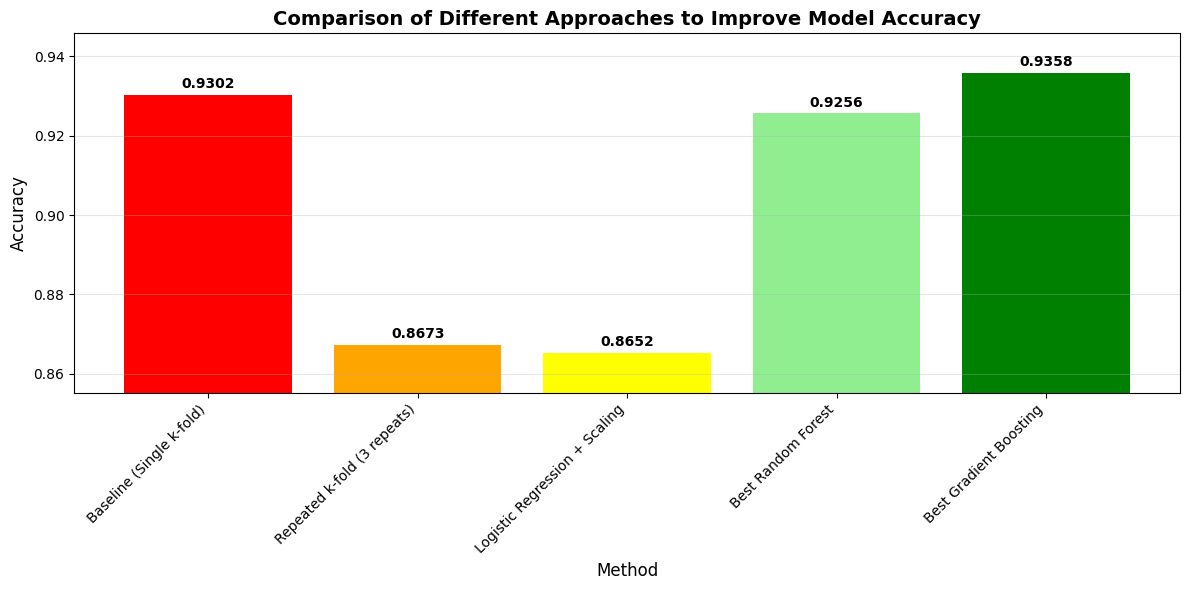

In [12]:
# Create a bar chart comparing all methods
methods = list(all_results.keys())
accuracies = list(all_results.values())

plt.figure(figsize=(12, 6))
bars = plt.bar(range(len(methods)), accuracies, color=['red', 'orange', 'yellow', 'lightgreen', 'green'])
plt.xlabel('Method', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Comparison of Different Approaches to Improve Model Accuracy', fontsize=14, fontweight='bold')
plt.xticks(range(len(methods)), methods, rotation=45, ha='right')
plt.ylim([min(accuracies) - 0.01, max(accuracies) + 0.01])
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, (bar, acc) in enumerate(zip(bars, accuracies)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001, 
             f'{acc:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

## Conclusions and Key Learnings

### What We Learned:

1. **Repeated k-Fold Cross-Validation Benefits:**
   - Provides more stable and reliable performance estimates
   - Reduces variance in model evaluation
   - Standard error decreases with more repeats (5-10 repeats is optimal)

2. **Improvement Strategies:**
   - Feature scaling can improve model performance
   - Different algorithms have different strengths on the same data
   - Ensemble methods (Random Forest, Gradient Boosting) often outperform linear models
   - Hyperparameter tuning can provide additional performance gains

3. **Best Practices:**
   - Always use pipelines to prevent data leakage during cross-validation
   - Test multiple algorithms before settling on one
   - Use appropriate number of repeats to balance accuracy and computational cost
   - Monitor both mean performance and standard deviation/error

### Model Selection Recommendation:
Based on the analysis, the best performing configuration should be used for this classification task, 
with the understanding that repeated k-fold cross-validation provides the most reliable performance estimate.